In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import contextily as cx
import numpy as np

In [4]:
members = gpd.read_file('member_list.geojson', index_col=0)
committee_members = gpd.read_file('committee_list.geojson', index_col=0)

In [26]:
members.head()

,OBJECTID,DISTRICT,DISTRICTN,Shape__Area,Shape__Length,district,name,party,town,title,county,first,last,geometry
0,1.0,1,1.0,1.015617,5.697749,1,Austin L. Theriault,R,Fort Kent,Rep,NaN,Austin,Theriault,"POLYGON ((-7794945.243 5872736.507, -7794926.6..."
1,2.0,2,2.0,0.196869,2.702875,2,Roger Clarence Albert,R,Madawaska,Rep,NaN,Roger,Albert,"POLYGON ((-7634509.982 5929516.153, -7634461.6..."
2,3.0,3,3.0,0.135217,2.322889,3,Mark Michael Babin,R,Fort Fairfield,Rep,NaN,Mark,Babin,"POLYGON ((-7560998.014 5891057.138, -7561039.6..."
3,4.0,4,4.0,0.046235,1.176316,4,Timothy C. Guerrette,R,Caribou,Rep,NaN,Timothy,Guerrette,"POLYGON ((-7603178.654 5900905.021, -7603176.9..."
4,5.0,5,5.0,0.023634,0.622563,5,Joseph F. Underwood,R,Presque Isle,Rep,NaN,Joseph,Underwood,"POLYGON ((-7576018.025 5905536.960, -7575707.6..."


In [27]:
committee_members.head()

,committee,title,name,role,party,town,first,last,match_name,name_y,geometry
0,"Agriculture, Conservation and Forestry",Rep,William D. Pluecker,Chair,I,Warren,William,Pluecker,William D. Pluecker,William D. Pluecker,"POLYGON ((-7716837.323 5492239.366, -7717089.1..."
1,"Agriculture, Conservation and Forestry",Rep,Allison Hepler,NaN,D,Woolwich,Allison,Hepler,Allison Hepler,Allison Hepler,"POLYGON ((-7779909.740 5420198.366, -7779908.8..."
2,Marine Resources,Rep,Allison Hepler,Chair,D,Woolwich,Allison,Hepler,Allison Hepler,Allison Hepler,"POLYGON ((-7779909.740 5420198.366, -7779908.8..."
3,"Agriculture, Conservation and Forestry",Rep,Laurie Osher,NaN,D,Orono,Laurie,Osher,Laurie Osher,Laurie Osher,"POLYGON ((-7647224.550 5597196.034, -7647265.8..."
4,"Agriculture, Conservation and Forestry",Rep,Rebecca L. Jauch,NaN,D,Topsham,Rebecca,Jauch,Rebecca L. Jauch,Rebecca L. Jauch,"POLYGON ((-7784715.739 5451823.711, -7784793.4..."


In [5]:
maine_boundary = gpd.read_file("https://services1.arcgis.com/RbMX0mRVOFNTdLzd/arcgis/rest/services/Maine_State_Boundary_Polygon/FeatureServer/0/query?where=1=1&outSR=3857&f=geojson")

In [6]:
senators = members[members["title"] == 'Sen']
representatives =  members[members["title"] == 'Rep']

Text(0.5, 0.98, 'Party Representation by District')

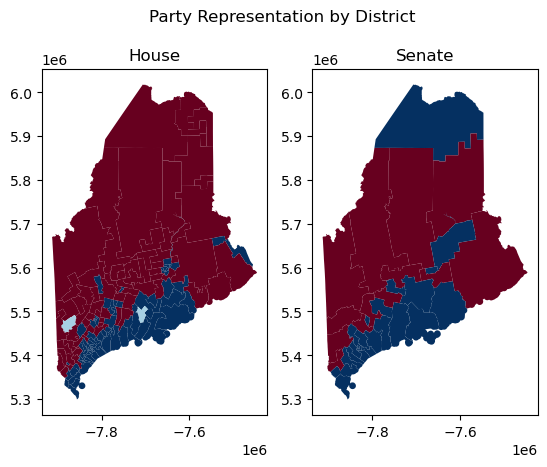

In [7]:
fig, axs = plt.subplots(1,2)
representatives.plot("party", ax=axs[0], cmap='RdBu_r')
axs[0].set_title("House")
senators.plot("party", ax=axs[1], cmap='RdBu_r')
axs[1].set_title("Senate")
fig.suptitle("Party Representation by District")

# Committee Breakdowns

In [8]:
# How many members are on each committee?
committee_members.groupby("committee")["name"].count()

committee
Agriculture, Conservation and Forestry                        13
Appropriations and Financial Affairs                          13
Criminal Justice and Public Safety                            13
Education and Cultural Affairs                                13
Energy, Utilities and Technology                              13
Environment and Natural Resources                             13
Government Oversight Committee                                12
Health Coverage, Insurance and Financial Services             13
Health and Human Services                                     13
Inland Fisheries and Wildlife                                 13
Innovation, Development, Economic Advancement and Business    13
Joint Select Committee on Housing                             13
Judiciary                                                     14
Labor and Housing                                             13
Marine Resources                                              13
State and Local

Text(0, 0.5, 'Number of Members')

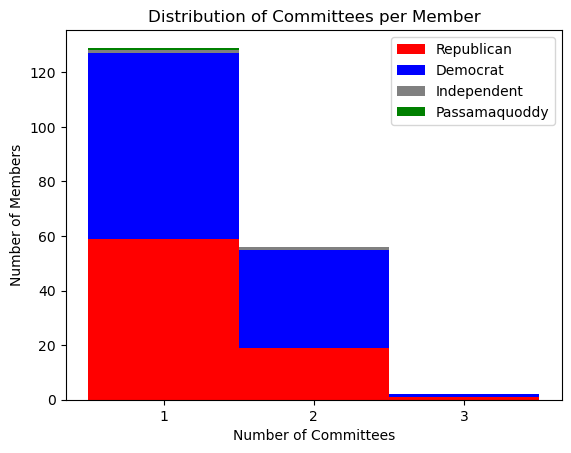

In [9]:
# How many committees is each member on?
committee_counts = committee_members.groupby(["party","name"]).count()["committee"]
plt.hist(
    [committee_counts['R'], committee_counts['D'], committee_counts['I'], committee_counts['Passamaquoddy Tribe']],
    range(1,5),
    stacked=True,
    color=['r', 'b','gray','g'],
    label=["Republican","Democrat", "Independent", "Passamaquoddy"],
    align='left'
    )
plt.gca().xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
plt.legend()
plt.title("Distribution of Committees per Member")
plt.xlabel("Number of Committees")
plt.ylabel("Number of Members")

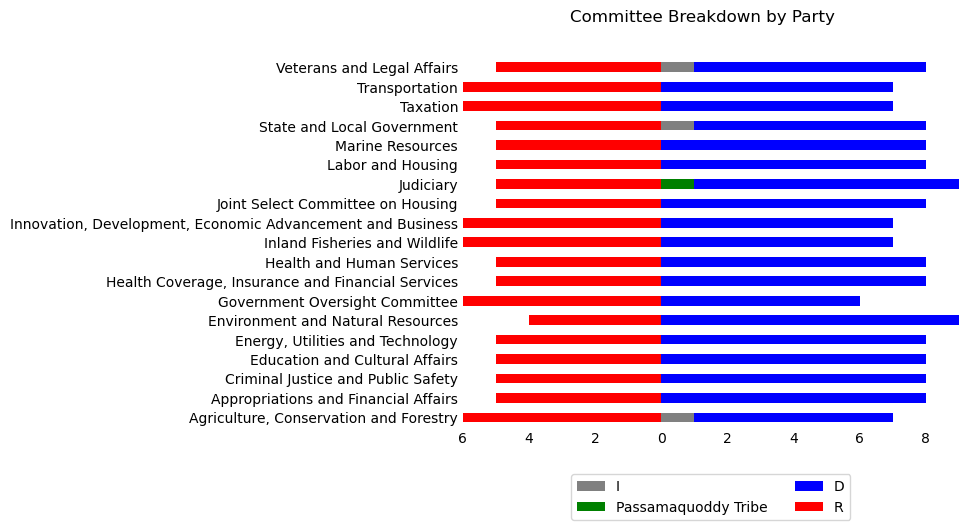

In [10]:
# partisanship by committee
fig, ax = plt.subplots()
fig.suptitle("Committee Breakdown by Party")

# count committee members by party
committee_counts = committee_members.groupby(["committee", "party"])["name"].count()
committee_counts.loc[:, "R"] = committee_counts.loc[:, "R"].values * -1

# reorder
plot_order = ["I", "Passamaquoddy Tribe", "D", "R"]
color_order = ["gray", "g", "b", "r"]

# plot bar charts, sorting by lean (second plot will follow the same sorting automatically)
committee_counts.unstack()[plot_order].plot(kind='barh', ax=ax, color=color_order, stacked=True).legend(bbox_to_anchor =(0.5,-0.27), loc='lower center', ncol=2)
ax.set_xlim(committee_counts.min(), committee_counts.max())
# scale and format both subplots
ax.set_ylabel("")
ax.set_frame_on(False)
ax.xaxis.set_major_formatter(lambda x, pos: str(int(abs(x))))
ax.tick_params(axis='both', which='both',length=0)


# Exploring the Geography of Committees

In [11]:
# How many from each party?
members.groupby("party").count()["name"].sort_values(ascending=False)

party
D                      104
R                       80
I                        2
Passamaquoddy Tribe      1
Name: name, dtype: int64

Text(0.5, 1.0, 'ACF Committee Member Districts')

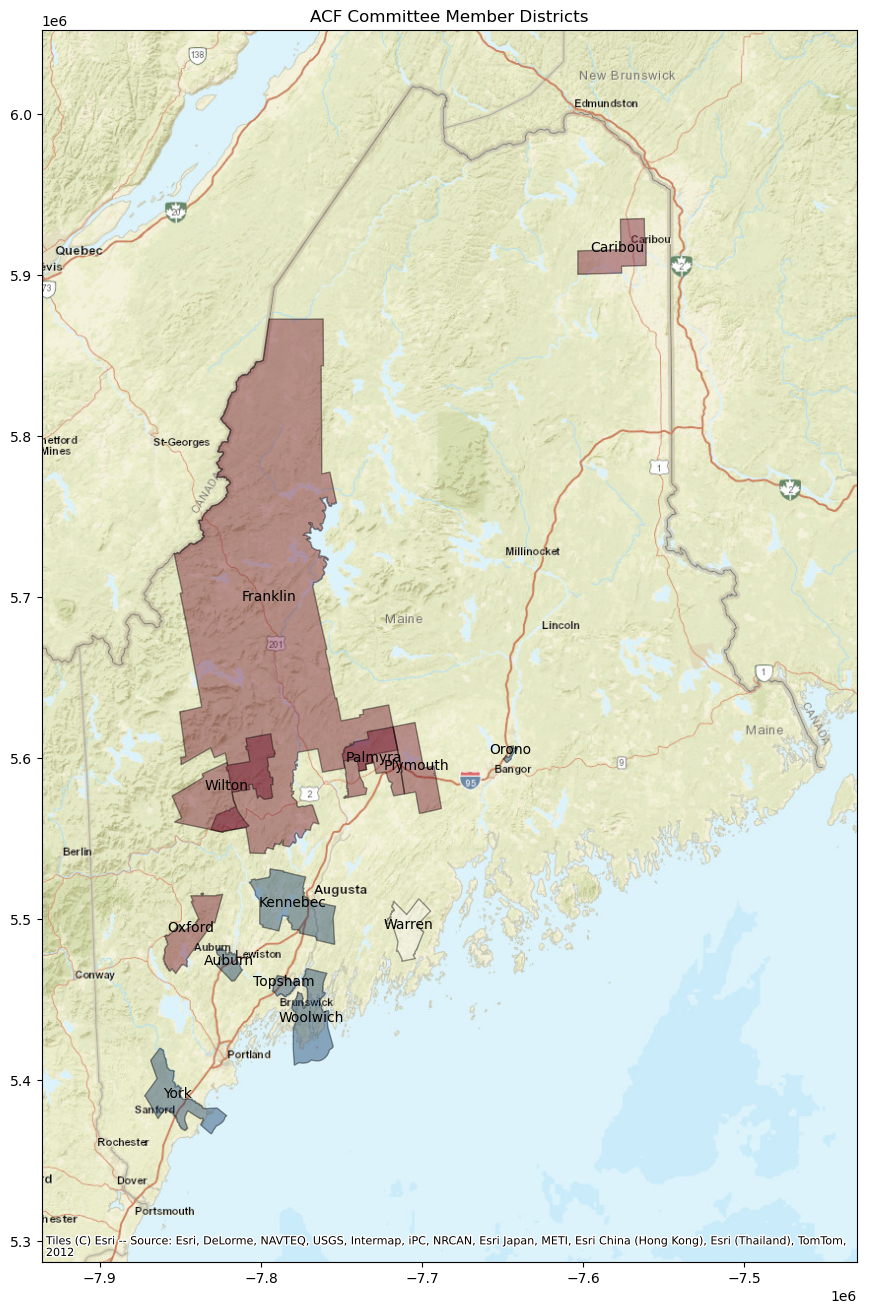

In [30]:
fig, ax = plt.subplots(figsize=(16,16))
maine_boundary.plot(ax=ax, edgecolor='k', alpha=0)
committee_members[(committee_members["committee"] == "Agriculture, Conservation and Forestry") & (committee_members['title'] == 'Sen')].plot("party", ax=ax, cmap='RdBu_r', alpha=0.4, edgecolor='k')
committee_members[(committee_members["committee"] == "Agriculture, Conservation and Forestry") & (committee_members['title'] == 'Rep')].plot("party", ax=ax, cmap='RdBu_r', alpha=0.4, edgecolor='k')
committee_members[(committee_members["committee"] == "Agriculture, Conservation and Forestry")].apply(lambda x: ax.annotate(text=f'{x.town}', xy=x.geometry.centroid.coords[0], ha='center'), axis=1)
cx.add_basemap(ax, source=cx.providers.Esri.WorldStreetMap)
ax.set_title("ACF Committee Member Districts")